In [2]:
import pandas as pd

customers = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/Customer.csv")
geolocation = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/geolocation.csv")
orders = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/orders.csv")
order_items = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/order_items.csv")
payments = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/order_payments.csv")
reviews = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/order_reviews.csv")
products = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/products.csv")
sellers = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/sellers.csv")
category_translation = pd.read_csv("C:/Users/kunja/Desktop/Brazilian_Ecommerce_Project/Data/product_category_name_translation.csv")

In [46]:
# Keep original data safe
customers_clean = customers.copy()
geolocation_clean = geolocation.copy()
orders_clean = orders.copy()
order_items_clean = order_items.copy()
payments_clean = payments.copy()
reviews_clean = reviews.copy()
products_clean = products.copy()
sellers_clean = sellers.copy()
category_translation_clean = category_translation.copy()

# Store all cleaned DataFrames in one dictionary
dfs = {
    "customers": customers_clean,
    "geolocation": geolocation_clean,
    "orders": orders_clean,
    "order_items": order_items_clean,
    "payments": payments_clean,
    "reviews": reviews_clean,
    "products": products_clean,
    "sellers": sellers_clean,
    "category_translation": category_translation_clean
}

print("All 9 datasets copied successfully.")

All 9 datasets copied successfully.


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

profile = []

for name, df in dfs.items():
    profile.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Duplicate_Rows": int(df.duplicated().sum()),
        "Missing_Cells": int(df.isnull().sum().sum()),
        "Memory_MB": round(
            df.memory_usage(deep=True).sum() / (1024**2), 2
        )
    })

profile_df = pd.DataFrame(profile)
display(profile_df)

NameError: name 'dfs' is not defined

In [4]:
for name, df in dfs.items():
    print(f"\n{'=' * 60}")
    print(f"DATASET: {name.upper()}")
    print("=" * 60)
    df.info()
    display(df.head(5))

NameError: name 'dfs' is not defined

In [5]:
missing_report = []

for name, df in dfs.items():
    for col in df.columns:
        missing_count = int(df[col].isnull().sum())

        missing_report.append({
            "Dataset": name,
            "Column": col,
            "Missing_Count": missing_count,
            "Missing_Percentage": round(
                missing_count / len(df) * 100, 2
            ) if len(df) else 0
        })

missing_df = pd.DataFrame(missing_report)

missing_df = missing_df[
    missing_df["Missing_Count"] > 0
].sort_values(
    "Missing_Percentage", ascending=False
)

display(missing_df)

,Dataset,Column,Missing_Count,Missing_Percentage
33,reviews,review_comment_title,87656,88.34
34,reviews,review_comment_message,58247,58.70
16,orders,order_delivered_customer_date,2965,2.98
38,products,product_category_name,610,1.85
39,products,product_name_lenght,610,1.85
40,products,product_description_lenght,610,1.85
41,products,product_photos_qty,610,1.85
15,orders,order_delivered_carrier_date,1783,1.79
14,orders,order_approved_at,160,0.16
42,products,product_weight_g,2,0.01


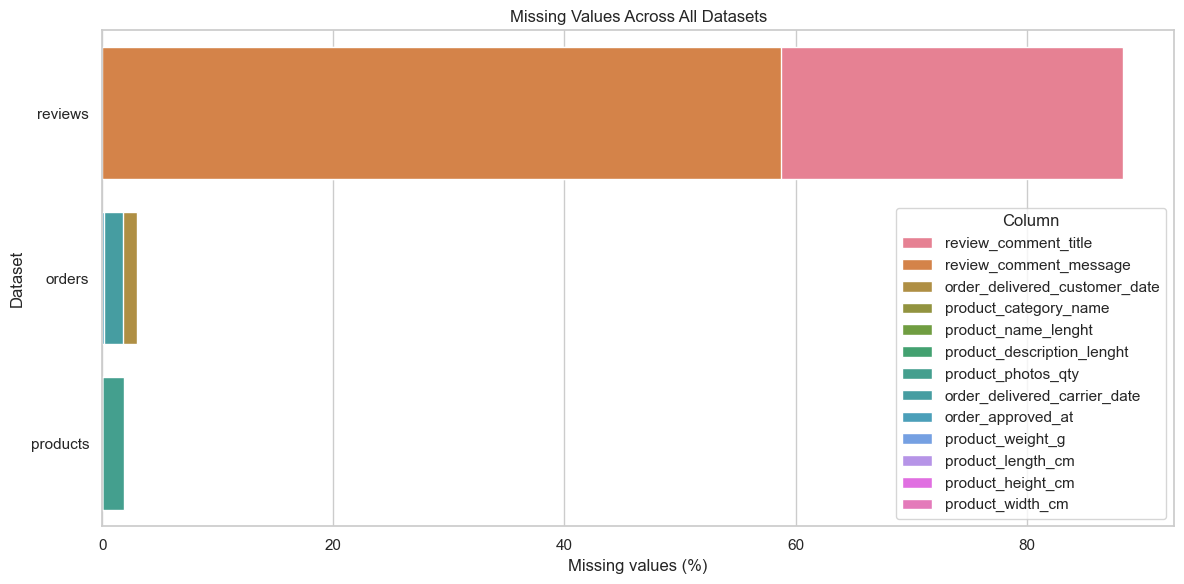

In [6]:
if not missing_df.empty:
    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=missing_df,
        x="Missing_Percentage",
        y="Dataset",
        hue="Column",
        dodge=False
    )

    plt.title("Missing Values Across All Datasets")
    plt.xlabel("Missing values (%)")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [7]:
duplicate_report = []

for name, df in dfs.items():
    duplicate_report.append({
        "Dataset": name,
        "Full_Duplicate_Rows": int(df.duplicated().sum())
    })

display(pd.DataFrame(duplicate_report))

,Dataset,Full_Duplicate_Rows
0,customers,0
1,geolocation,261836
2,orders,0
3,order_items,0
4,payments,0
5,reviews,0
6,products,0
7,sellers,0
8,category_translation,0


In [8]:
key_columns = {
    "customers": ["customer_id"],
    "orders": ["order_id"],
    "order_items": ["order_id", "order_item_id"],
    "payments": ["order_id", "payment_sequential"],
    "products": ["product_id"],
    "sellers": ["seller_id"],
    "category_translation": ["product_category_name"]
}

for name, keys in key_columns.items():
    df = dfs[name]

    print(f"\n{name.upper()} — keys: {keys}")
    print("Rows with null key:",
          int(df[keys].isnull().any(axis=1).sum()))
    print("Rows with duplicate key:",
          int(df.duplicated(subset=keys, keep=False).sum()))


CUSTOMERS — keys: ['customer_id']
Rows with null key: 0
Rows with duplicate key: 0

ORDERS — keys: ['order_id']
Rows with null key: 0
Rows with duplicate key: 0

ORDER_ITEMS — keys: ['order_id', 'order_item_id']
Rows with null key: 0
Rows with duplicate key: 0

PAYMENTS — keys: ['order_id', 'payment_sequential']
Rows with null key: 0
Rows with duplicate key: 0

PRODUCTS — keys: ['product_id']
Rows with null key: 0
Rows with duplicate key: 0

SELLERS — keys: ['seller_id']
Rows with null key: 0
Rows with duplicate key: 0

CATEGORY_TRANSLATION — keys: ['product_category_name']
Rows with null key: 0
Rows with duplicate key: 0


In [9]:
for name, df in dfs.items():
    # Standardize column names
    df.columns = (
        df.columns.str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

    # Remove leading/trailing whitespace from text columns
    text_cols = df.select_dtypes(
        include=["object", "string"]
    ).columns

    for col in text_cols:
        df[col] = df[col].str.strip()

print("Column names and text whitespace standardized.")

Column names and text whitespace standardized.


In [10]:
for col in ["order_status"]:
    if col in dfs["orders"].columns:
        dfs["orders"][col] = (
            dfs["orders"][col].str.lower()
        )

if "payment_type" in dfs["payments"].columns:
    dfs["payments"]["payment_type"] = (
        dfs["payments"]["payment_type"].str.lower()
    )

In [11]:
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col], errors="coerce"
    )

for col in ["review_creation_date", "review_answer_timestamp"]:
    reviews_clean[col] = pd.to_datetime(
        reviews_clean[col], errors="coerce"
    )

print(orders_clean[date_columns].dtypes)

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object


In [12]:
date_checks = {
    "Approval before purchase": (
        orders_clean["order_approved_at"]
        < orders_clean["order_purchase_timestamp"]
    ),
    "Carrier delivery before purchase": (
        orders_clean["order_delivered_carrier_date"]
        < orders_clean["order_purchase_timestamp"]
    ),
    "Customer delivery before purchase": (
        orders_clean["order_delivered_customer_date"]
        < orders_clean["order_purchase_timestamp"]
    ),
    "Customer delivery before carrier handoff": (
        orders_clean["order_delivered_customer_date"]
        < orders_clean["order_delivered_carrier_date"]
    )
}

for check_name, condition in date_checks.items():
    print(f"{check_name}: {int(condition.sum())} suspicious rows")

Approval before purchase: 0 suspicious rows
Carrier delivery before purchase: 161 suspicious rows
Customer delivery before purchase: 0 suspicious rows
Customer delivery before carrier handoff: 23 suspicious rows


In [13]:
for name, df in dfs.items():
    numeric_df = df.select_dtypes(include=np.number)

    if not numeric_df.empty:
        print(f"\n{name.upper()}")
        display(numeric_df.describe().T)


CUSTOMERS


,count,mean,std,min,25%,50%,75%,max
customer_zip_code_prefix,99441.0,35137.474583,29797.938996,1003.0,11347.0,24416.0,58900.0,99990.0



GEOLOCATION


,count,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,1000163.0,36574.166466,30549.335710,1001.000000,11075.000000,26530.000000,63504.000000,99990.000000
geolocation_lat,1000163.0,-21.176153,5.715866,-36.605374,-23.603546,-22.919377,-19.979620,45.065933
geolocation_lng,1000163.0,-46.390541,4.269748,-101.466766,-48.573172,-46.637879,-43.767709,121.105394



ORDER_ITEMS


,count,mean,std,min,25%,50%,75%,max
order_item_id,112650.0,1.197834,0.705124,1.00,1.00,1.00,1.00,21.00
price,112650.0,120.653739,183.633928,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.0,19.990320,15.806405,0.00,13.08,16.26,21.15,409.68


... (4 outputs left out)


PRODUCTS


,count,mean,std,min,25%,50%,75%,max
product_name_lenght,32341.0,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0



SELLERS


,count,mean,std,min,25%,50%,75%,max
seller_zip_code_prefix,3095.0,32291.059451,32713.45383,1001.0,7093.5,14940.0,64552.5,99730.0


In [14]:
print("Negative item prices:",
      (order_items_clean["price"] < 0).sum())

print("Negative freight values:",
      (order_items_clean["freight_value"] < 0).sum())

print("Non-positive item sequence:",
      (order_items_clean["order_item_id"] <= 0).sum())

print("Non-positive payment values:",
      (payments_clean["payment_value"] <= 0).sum())

print("Review scores outside 1–5:",
      (~reviews_clean["review_score"].between(1, 5)).sum())

Negative item prices: 0
Negative freight values: 0
Non-positive item sequence: 0
Non-positive payment values: 9
Review scores outside 1–5: 0


In [15]:
col = "price"

q1 = order_items_clean[col].quantile(0.25)
q3 = order_items_clean[col].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

price_outliers = order_items_clean[
    (order_items_clean[col] < lower_bound) |
    (order_items_clean[col] > upper_bound)
]

print("Price outliers:", len(price_outliers))
display(price_outliers.head(10))

Price outliers: 8427


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
7,000576fe39319847cbb9d288c5617fa6,1,557d850972a7d6f792fd18ae1400d9b6,5996cddab893a4652a15592fb58ab8db,07-10-2018 12:30,810.00,70.75
16,0009c9a17f916a706d71784483a5d643,1,3f27ac8e699df3d300ec4a5d8c5cf0b2,fcb5ace8bcc92f75707dc0f01a27d269,05-02-2018 9:31,639.00,11.34
26,0011d82c4b53e22e84023405fb467e57,1,c389f712c4b4510bc997cee93e8b1a28,bfd27a966d91cfaafdb25d076585f0da,1/29/2018 21:51,289.00,26.33
30,00137e170939bba5a3134e2386413108,1,672e757f331900b9deea127a2a7b79fd,e59aa562b9f8076dd550fcddf0e73491,11/30/2017 6:30,397.00,24.65
39,0017afd5076e074a48f1f1a4c7bac9c5,1,fe59a1e006df3ac42bf0ceb876d70969,25c5c91f63607446a97b143d2d535d31,4/24/2017 22:25,809.10,44.29
61,0025c5d1a8ca53a240ec2634bb4492ea,1,35537536ed2b4c561b4018bf3abf54e0,955fee9216a65b617aa5c0531780ce60,07-10-2018 9:30,390.00,29.39
65,00275bce676303c3bfd7292aefdfa223,1,6490b9f63b0b595e1c1402b46b0f50ad,99eaacc9e6046db1c82b163c5f84869f,12-04-2017 3:32,279.90,13.46
70,0029c5db35ef291ce99d1262012e7daa,1,7614c62b86a81021243e438cfde78ccc,900ba814c251a692506d7834c1218441,09-03-2018 3:50,492.75,21.62
99,0036887767dea4bd43b1a88cd0d9477a,1,3a264b078bf20e98f315ff65c23fa263,46dc3b2cc0980fb8ec44634e21d2718e,10/19/2017 1:07,399.99,23.64
158,006127b8b9a1681a982313ed7129c3c0,1,f819f0c84a64f02d3a5606ca95edd272,7d13fca15225358621be4086e1eb0964,3/15/2018 2:30,540.00,16.22


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

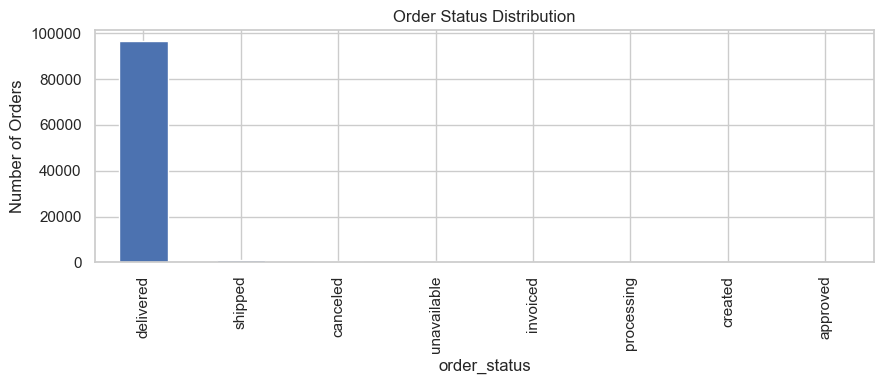

In [16]:
# Order status
display(orders_clean["order_status"].value_counts())

orders_clean["order_status"].value_counts().plot(
    kind="bar", figsize=(9, 4)
)
plt.title("Order Status Distribution")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

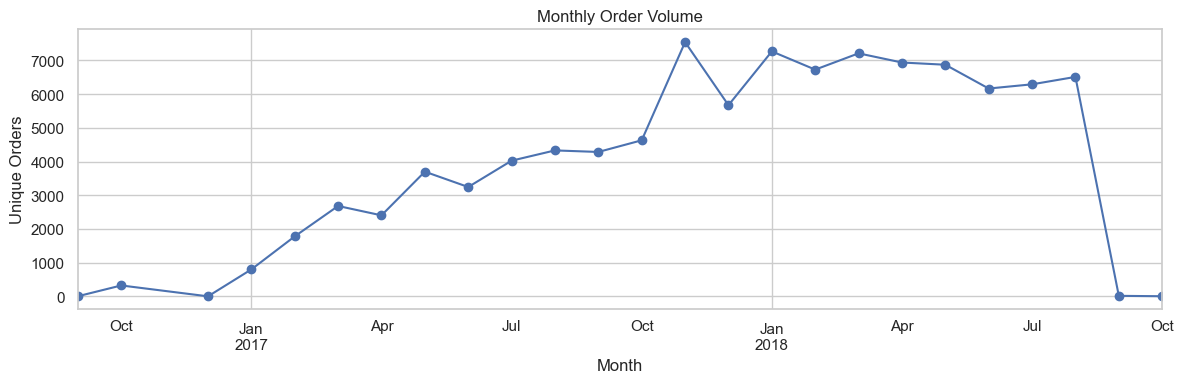

In [17]:
orders_clean["purchase_month"] = (
    orders_clean["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_orders = (
    orders_clean.groupby("purchase_month")["order_id"]
    .nunique()
)

monthly_orders.plot(figsize=(12, 4), marker="o")
plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Unique Orders")
plt.tight_layout()
plt.show()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


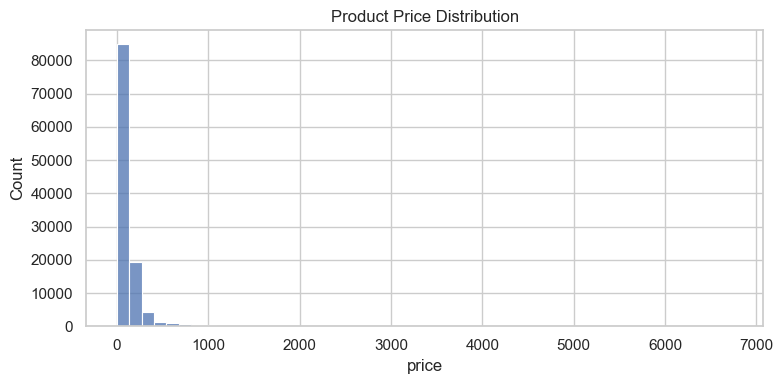

In [18]:
display(
    order_items_clean[["price", "freight_value"]].describe()
)

plt.figure(figsize=(8, 4))
sns.histplot(
    data=order_items_clean,
    x="price",
    bins=50
)
plt.title("Product Price Distribution")
plt.tight_layout()
plt.show()

In [19]:
print("Item revenue:", order_items_clean["price"].sum())
print("Freight total:", order_items_clean["freight_value"].sum())
print("Unique orders with items:",
      order_items_clean["order_id"].nunique())

Item revenue: 13591643.7
Freight total: 2251909.54
Unique orders with items: 98666


payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

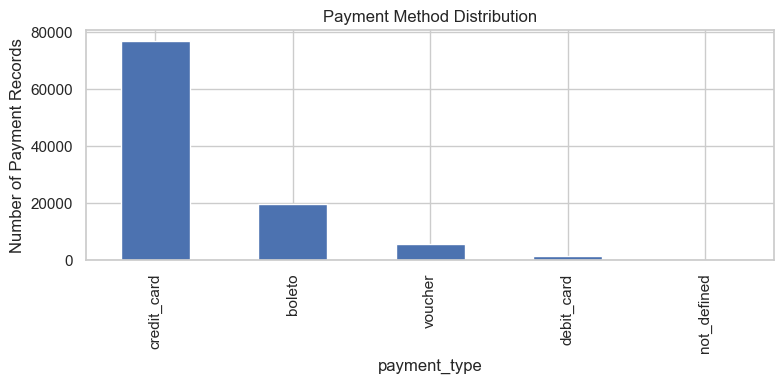

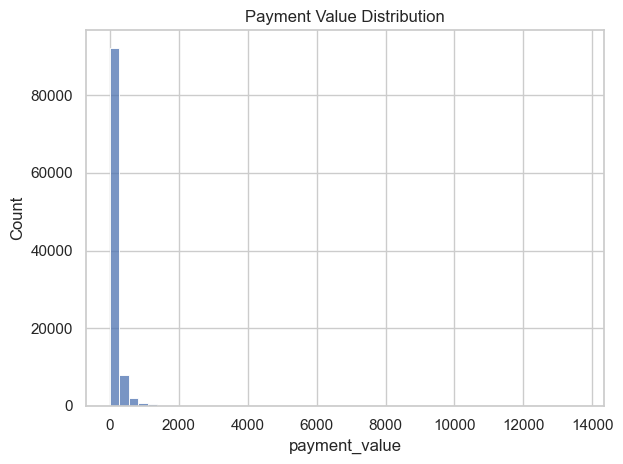

In [20]:
display(payments_clean["payment_type"].value_counts())

payments_clean["payment_type"].value_counts().plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Payment Method Distribution")
plt.ylabel("Number of Payment Records")
plt.tight_layout()
plt.show()

sns.histplot(
    data=payments_clean,
    x="payment_value",
    bins=50
)
plt.title("Payment Value Distribution")
plt.tight_layout()
plt.show()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

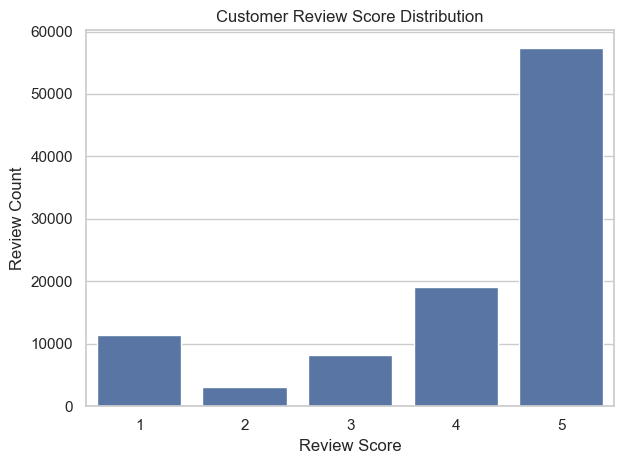

In [21]:
display(
    reviews_clean["review_score"]
    .value_counts()
    .sort_index()
)

sns.countplot(
    data=reviews_clean,
    x="review_score"
)
plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Review Count")
plt.tight_layout()
plt.show()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
Name: count, dtype: int64

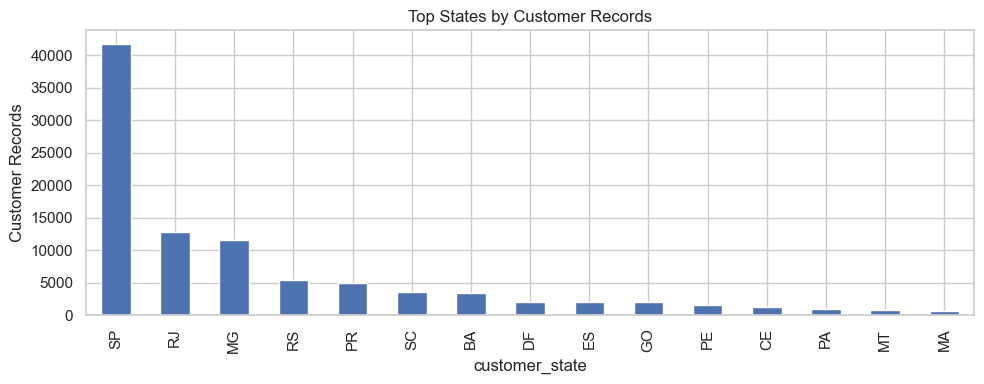

Unique customer identities: 96096


In [22]:
display(
    customers_clean["customer_state"]
    .value_counts()
    .head(15)
)

customers_clean["customer_state"].value_counts().head(15).plot(
    kind="bar", figsize=(10, 4)
)
plt.title("Top States by Customer Records")
plt.ylabel("Customer Records")
plt.tight_layout()
plt.show()

print(
    "Unique customer identities:",
    customers_clean["customer_unique_id"].nunique()
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_id,32951,32951,1e9e8ef04dbcff4541ed26657ea517e5,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category_name,32341,73,cama_mesa_banho,3029,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name_lenght,32341.0,NaN,NaN,NaN,48.476949,10.245741,5.0,42.0,51.0,57.0,76.0
product_description_lenght,32341.0,NaN,NaN,NaN,771.495285,635.115225,4.0,339.0,595.0,972.0,3992.0
product_photos_qty,32341.0,NaN,NaN,NaN,2.188986,1.736766,1.0,1.0,1.0,3.0,20.0
product_weight_g,32949.0,NaN,NaN,NaN,2276.472488,4282.038731,0.0,300.0,700.0,1900.0,40425.0
product_length_cm,32949.0,NaN,NaN,NaN,30.815078,16.914458,7.0,18.0,25.0,38.0,105.0
product_height_cm,32949.0,NaN,NaN,NaN,16.937661,13.637554,2.0,8.0,13.0,21.0,105.0
product_width_cm,32949.0,NaN,NaN,NaN,23.196728,12.079047,6.0,15.0,20.0,30.0,118.0


product_category_name
cama_mesa_banho                3029
esporte_lazer                  2867
moveis_decoracao               2657
beleza_saude                   2444
utilidades_domesticas          2335
automotivo                     1900
informatica_acessorios         1639
brinquedos                     1411
relogios_presentes             1329
telefonia                      1134
bebes                           919
perfumaria                      868
fashion_bolsas_e_acessorios     849
papelaria                       849
cool_stuff                      789
Name: count, dtype: int64

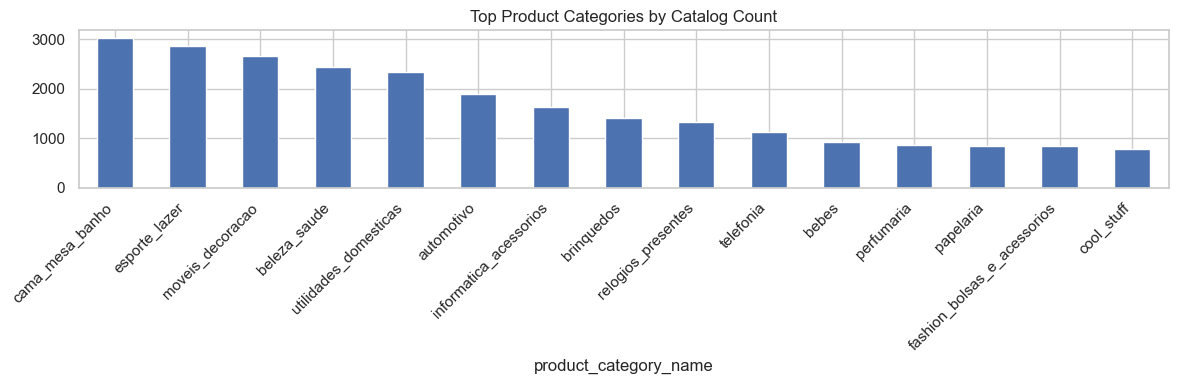

In [23]:
display(products_clean.describe(include="all").T)

display(
    products_clean["product_category_name"]
    .value_counts(dropna=False)
    .head(15)
)

products_clean["product_category_name"].value_counts().head(15).plot(
    kind="bar", figsize=(12, 4)
)
plt.title("Top Product Categories by Catalog Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [24]:
display(
    sellers_clean["seller_state"].value_counts().head(15)
)

print("Unique sellers:", sellers_clean["seller_id"].nunique())

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
RN       5
MS       5
Name: count, dtype: int64

Unique sellers: 3095


In [25]:
display(geolocation_clean.describe(include="all").T)

print(
    "Unique ZIP prefixes:",
    geolocation_clean["geolocation_zip_code_prefix"].nunique()
)

print(
    "Duplicate complete rows:",
    geolocation_clean.duplicated().sum()
)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
geolocation_zip_code_prefix,1000163.0,NaN,NaN,NaN,36574.166466,30549.33571,1001.0,11075.0,26530.0,63504.0,99990.0
geolocation_lat,1000163.0,NaN,NaN,NaN,-21.176153,5.715866,-36.605374,-23.603546,-22.919377,-19.97962,45.065933
geolocation_lng,1000163.0,NaN,NaN,NaN,-46.390541,4.269748,-101.466766,-48.573172,-46.637879,-43.767709,121.105394
geolocation_city,1000163,8010,sao paulo,135800,NaN,NaN,NaN,NaN,NaN,NaN,NaN
geolocation_state,1000163,27,SP,404268,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Unique ZIP prefixes: 19015
Duplicate complete rows: 261836


In [26]:
invalid_coordinates = geolocation_clean[
    ~geolocation_clean["geolocation_lat"].between(-90, 90) |
    ~geolocation_clean["geolocation_lng"].between(-180, 180)
]

print("Invalid coordinate rows:", len(invalid_coordinates))

Invalid coordinate rows: 0


In [27]:
display(category_translation_clean.head())

print("Rows:", len(category_translation_clean))
print("Duplicate rows:", category_translation_clean.duplicated().sum())
print(
    "Duplicate Portuguese category keys:",
    category_translation_clean.duplicated(
        subset=["product_category_name"],
        keep=False
    ).sum()
)

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


Rows: 71
Duplicate rows: 0
Duplicate Portuguese category keys: 0


In [28]:
# Orders without a matching customer
print(
    "Orders with missing customer:",
    (~orders_clean["customer_id"].isin(
        customers_clean["customer_id"]
    )).sum()
)

# Order items without a matching order
print(
    "Items with missing order:",
    (~order_items_clean["order_id"].isin(
        orders_clean["order_id"]
    )).sum()
)

# Order items without a matching product
print(
    "Items with missing product:",
    (~order_items_clean["product_id"].isin(
        products_clean["product_id"]
    )).sum()
)

# Order items without a matching seller
print(
    "Items with missing seller:",
    (~order_items_clean["seller_id"].isin(
        sellers_clean["seller_id"]
    )).sum()
)

# Payments without a matching order
print(
    "Payments with missing order:",
    (~payments_clean["order_id"].isin(
        orders_clean["order_id"]
    )).sum()
)

Orders with missing customer: 0
Items with missing order: 0
Items with missing product: 0
Items with missing seller: 0
Payments with missing order: 0


In [29]:
# Aggregate order items to one row per order
item_summary = (
    order_items_clean.groupby("order_id")
    .agg(
        item_revenue=("price", "sum"),
        freight_total=("freight_value", "sum"),
        item_count=("order_item_id", "count")
    )
    .reset_index()
)

# Aggregate payments to one row per order
payment_summary = (
    payments_clean.groupby("order_id")
    .agg(
        payment_total=("payment_value", "sum"),
        payment_count=("payment_sequential", "count")
    )
    .reset_index()
)

# Aggregate review scores to one row per order
review_summary = (
    reviews_clean.groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        review_count=("review_id", "count")
    )
    .reset_index()
)

# Build the master table
master = (
    orders_clean
    .merge(
        customers_clean,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )
    .merge(
        item_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        payment_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
    .merge(
        review_summary,
        on="order_id",
        how="left",
        validate="one_to_one"
    )
)

print("Orders:", len(orders_clean))
print("Master rows:", len(master))
print("Unique master orders:", master["order_id"].nunique())

display(master.head())

Orders: 99441
Master rows: 99441
Unique master orders: 99441


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,purchase_month,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,item_revenue,freight_total,item_count,payment_total,payment_count,average_review_score,review_count
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:00,2017-10-02 11:07:00,2017-10-04 19:55:00,2017-10-10 21:25:00,2017-10-18,2017-10,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,29.99,8.72,1.0,38.71,3.0,4.0,1.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:00,2018-07-26 03:24:00,2018-07-26 14:31:00,2018-08-07 15:27:00,2018-08-13,2018-07,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,118.70,22.76,1.0,141.46,1.0,4.0,1.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:00,2018-08-08 08:55:00,2018-08-08 13:50:00,2018-08-17 18:06:00,2018-09-04,2018-08,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,159.90,19.22,1.0,179.12,1.0,5.0,1.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:00,2017-11-18 19:45:00,2017-11-22 13:39:00,2017-12-02 00:28:00,2017-12-15,2017-11,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,45.00,27.20,1.0,72.20,1.0,5.0,1.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:00,2018-02-13 22:20:00,2018-02-14 19:46:00,2018-02-16 18:17:00,2018-02-26,2018-02,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,19.90,8.72,1.0,28.62,1.0,5.0,1.0


In [30]:
master["delivery_days"] = (
    master["order_delivered_customer_date"]
    - master["order_purchase_timestamp"]
).dt.total_seconds() / 86400

master["delay_days"] = (
    master["order_delivered_customer_date"]
    - master["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivered = master[
    master["order_status"].eq("delivered")
].copy()

print("Average delivery days:", delivered["delivery_days"].mean())
print("Median delivery days:", delivered["delivery_days"].median())

delivered["late_delivery"] = delivered["delay_days"] > 0

print(
    "Late delivery rate (%):",
    round(delivered["late_delivery"].mean() * 100, 2)
)

Average delivery days: 12.558173691015053
Median delivery days: 10.217708333333334
Late delivery rate (%): 8.11


In [31]:
review_by_delivery = (
    delivered.groupby("late_delivery")["average_review_score"]
    .agg(["count", "mean", "median"])
)

display(review_by_delivery)

,count,mean,median
late_delivery,,,
False,88171,4.294311,5.0
True,7661,2.566506,2.0


In [32]:
reconciliation = item_summary.merge(
    payment_summary,
    on="order_id",
    how="outer",
    indicator=True
)

reconciliation["expected_item_freight"] = (
    reconciliation["item_revenue"]
    + reconciliation["freight_total"]
)

reconciliation["payment_difference"] = (
    reconciliation["payment_total"]
    - reconciliation["expected_item_freight"]
)

display(
    reconciliation.assign(
        absolute_difference=lambda x:
            x["payment_difference"].abs()
    ).sort_values(
        "absolute_difference", ascending=False
    ).head(20)
)

,order_id,item_revenue,freight_total,item_count,payment_total,payment_count,_merge,expected_item_freight,payment_difference,absolute_difference
80176,ce6d150fb29ada17d2082f4847107665,1299.00,104.66,1.0,1586.47,1.0,both,1403.66,182.81,182.81
42865,6e5fe7366a2e1bfbf3257dba0af1267f,179.19,108.72,6.0,406.92,1.0,both,287.91,119.01,119.01
43791,70b742795bc441e94a44a084b6d9ce7a,269.99,196.94,1.0,578.82,1.0,both,466.93,111.89,111.89
59228,996c7e73600ad3723e8627ab7bef81e4,559.90,28.00,1.0,664.43,1.0,both,587.90,76.53,76.53
43794,70b7e94ea46d3e8b5bc12a50186edaf0,167.88,45.27,3.0,274.84,1.0,both,213.15,61.69,61.69
73090,bc2c82b0ef78d2252b6176d1972db7c9,165.00,77.01,3.0,303.02,1.0,both,242.01,61.01,61.01
68015,af9ffff2ce6b3defd34fd4c78857a379,395.65,17.52,1.0,466.97,1.0,both,413.17,53.80,53.80
14745,262118ce178bb3e4590a3adcf6d62e6b,119.80,57.94,2.0,126.12,1.0,both,177.74,-51.62,51.62
74503,bfdb5bbb06458d600a33d61f5f287472,297.00,51.93,1.0,394.36,1.0,both,348.93,45.43,45.43
54744,8d9c0dc8d5a2ce804f6b925d8f8e6c1d,209.80,44.65,2.0,293.89,1.0,both,254.45,39.44,39.44


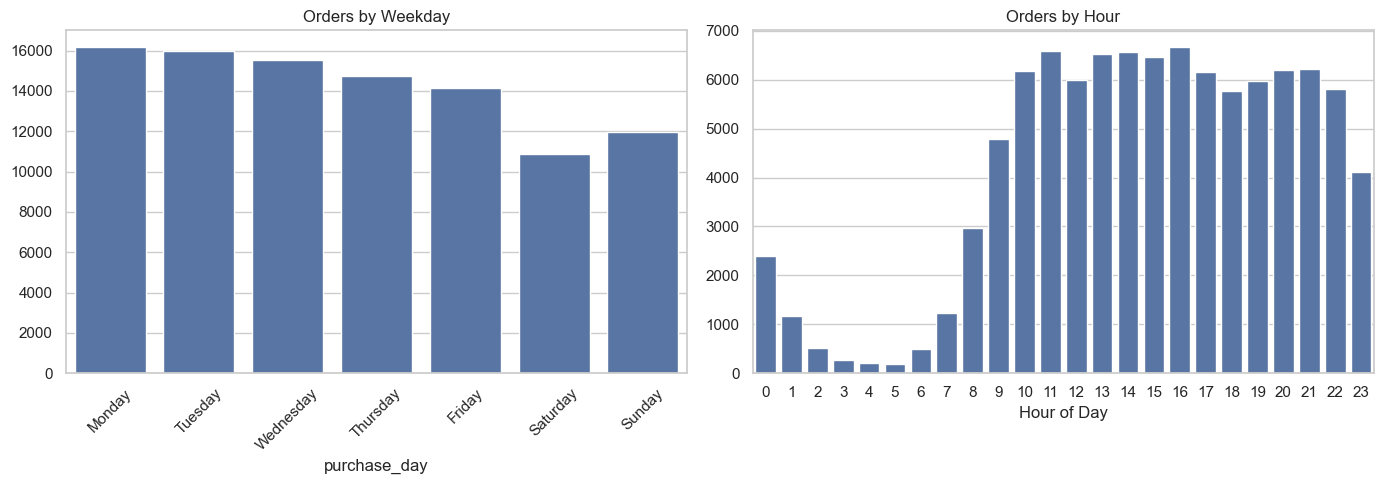

In [7]:
orders["purchase_day"] = (
    orders["order_purchase_timestamp"].dt.day_name()
)
orders["purchase_hour"] = (
    orders["order_purchase_timestamp"].dt.hour
)

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_counts = (
    orders["purchase_day"]
    .value_counts()
    .reindex(day_order)
)

hour_counts = (
    orders["purchase_hour"]
    .value_counts()
    .sort_index()
)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    x=weekday_counts.index,
    y=weekday_counts.values,
    ax=ax[0]
)
ax[0].set_title("Orders by Weekday")
ax[0].tick_params(axis="x", rotation=45)

sns.barplot(
    x=hour_counts.index,
    y=hour_counts.values,
    ax=ax[1]
)
ax[1].set_title("Orders by Hour")
ax[1].set_xlabel("Hour of Day")

plt.tight_layout()
plt.show()

In [8]:
order_sales = (
    order_items.groupby("order_id")
    .agg(
        item_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        item_lines=("order_item_id", "count"),
        unique_products=("product_id", "nunique"),
        unique_sellers=("seller_id", "nunique")
    )
    .reset_index()
)

total_item_sales = order_sales["item_revenue"].sum()
total_freight = order_sales["freight_revenue"].sum()
orders_with_items = order_sales["order_id"].nunique()
aov = total_item_sales / orders_with_items

print(f"Total item sales: {total_item_sales:,.2f}")
print(f"Total freight: {total_freight:,.2f}")
print(f"Orders with items: {orders_with_items:,}")
print(f"Average item sales per order: {aov:,.2f}")

display(order_sales.describe().T)

Total item sales: 13,591,643.70
Total freight: 2,251,909.54
Orders with items: 98,666
Average item sales per order: 137.75


,count,mean,std,min,25%,50%,75%,max
item_revenue,98666.0,137.754076,210.645145,0.85,45.90,86.90,149.90,13440.00
freight_revenue,98666.0,22.823562,21.650909,0.00,13.85,17.17,24.04,1794.96
item_lines,98666.0,1.141731,0.538452,1.00,1.00,1.00,1.00,21.00
unique_products,98666.0,1.038098,0.226456,1.00,1.00,1.00,1.00,8.00
unique_sellers,98666.0,1.013622,0.122297,1.00,1.00,1.00,1.00,5.00


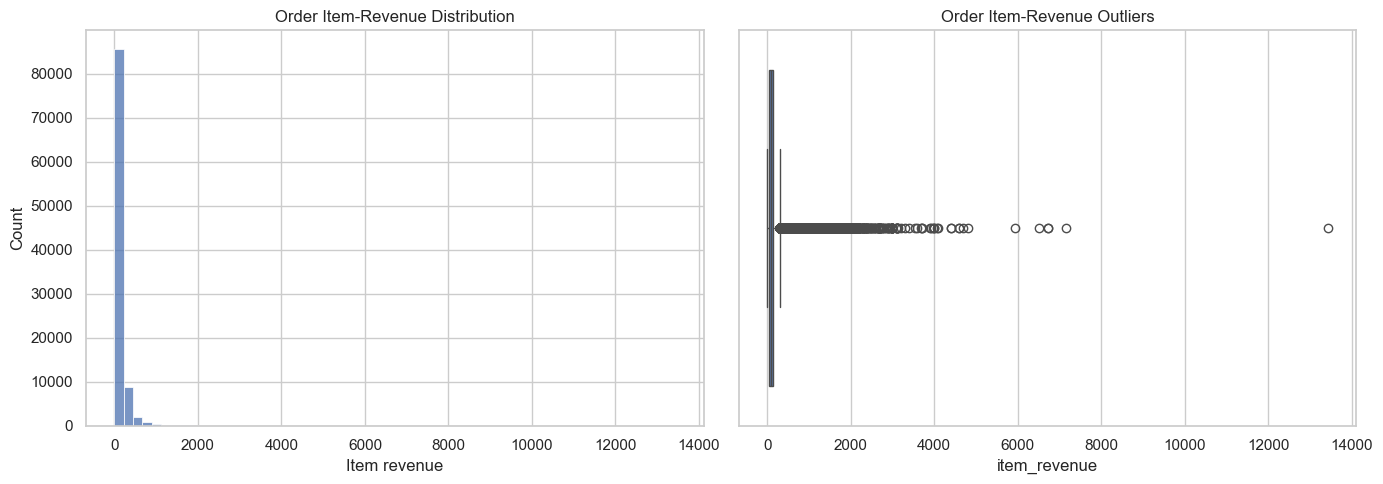

count    98666.000000
mean       137.754076
std        210.645145
min          0.850000
25%         45.900000
50%         86.900000
75%        149.900000
90%        269.900000
95%        399.900000
99%        998.900000
max      13440.000000
Name: item_revenue, dtype: float64

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    order_sales["item_revenue"],
    bins=60,
    ax=ax[0]
)
ax[0].set_title("Order Item-Revenue Distribution")
ax[0].set_xlabel("Item revenue")

sns.boxplot(
    x=order_sales["item_revenue"],
    ax=ax[1]
)
ax[1].set_title("Order Item-Revenue Outliers")

plt.tight_layout()
plt.show()

display(
    order_sales["item_revenue"]
    .describe(percentiles=[.25, .5, .75, .90, .95, .99])
)

In [10]:
high_value_orders = order_sales[
    order_sales["item_revenue"] >=
    order_sales["item_revenue"].quantile(0.95)
].sort_values("item_revenue", ascending=False)

display(high_value_orders.head(20))

,order_id,item_revenue,freight_revenue,item_lines,unique_products,unique_sellers
1455,03caa2c082116e1d31e67e9ae3700499,13440.00,224.08,8,1,1
44467,736e1922ae60d0d6a89247b851902527,7160.00,114.88,4,1,1
3130,0812eb902a67711a1cb742b3cdaa65ae,6735.00,194.31,1,1,1
98298,fefacc66af859508bf1a7934eab1e97f,6729.00,193.21,1,1,1
94439,f5136e38d1a14a4dbd87dff67da82701,6499.00,227.66,1,1,1
17114,2cc9089445046817a7539d90805e6e5a,5934.60,146.94,6,1,1
65046,a96610ab360d42a2e5335a3998b4718a,4799.00,151.34,1,1,1
9868,199af31afc78c699f0dbf71fb178d4d4,4690.00,74.34,1,1,1
69531,b4c4b76c642808cbe472a32b86cddc95,4599.90,209.54,2,1,1
54353,8dbc85d1447242f3b127dda390d56e19,4590.00,91.78,1,1,1


In [11]:
sales_orders = orders[
    ["order_id", "order_purchase_timestamp", "order_status"]
].merge(
    order_sales,
    on="order_id",
    how="left",
    validate="one_to_one"
)

sales_orders["purchase_month"] = (
    sales_orders["order_purchase_timestamp"]
    .dt.to_period("M")
)

monthly_sales = (
    sales_orders.groupby("purchase_month")
    .agg(
        orders=("order_id", "nunique"),
        item_sales=("item_revenue", "sum"),
        freight=("freight_revenue", "sum")
    )
    .reset_index()
)

monthly_sales["aov"] = (
    monthly_sales["item_sales"] / monthly_sales["orders"]
)

monthly_sales["purchase_month"] = (
    monthly_sales["purchase_month"].astype(str)
)

display(monthly_sales.tail(24))

,purchase_month,orders,item_sales,freight,aov
1,2016-10,324,49507.66,7301.18,152.801420
2,2016-12,1,10.90,8.72,10.900000
3,2017-01,800,120312.87,16875.62,150.391087
4,2017-02,1780,247303.02,38977.60,138.934281
5,2017-03,2682,374344.30,57704.29,139.576547
6,2017-04,2404,359927.23,52495.01,149.720146
7,2017-05,3700,506071.14,80119.81,136.775984
8,2017-06,3245,433038.60,69924.44,133.447951
9,2017-07,4026,498031.48,86940.14,123.703795
10,2017-08,4331,573971.68,94232.92,132.526363


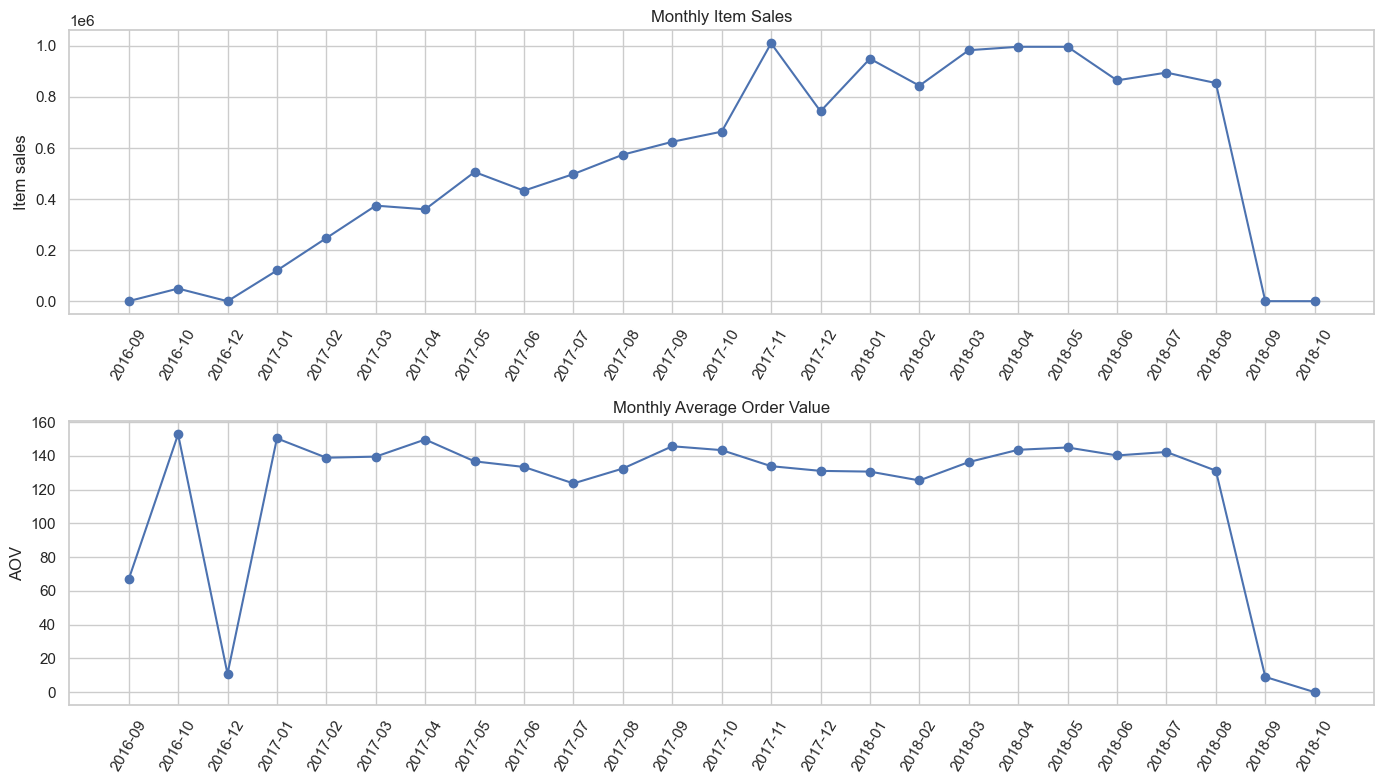

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(14, 8))

ax[0].plot(
    monthly_sales["purchase_month"],
    monthly_sales["item_sales"],
    marker="o"
)
ax[0].set_title("Monthly Item Sales")
ax[0].set_ylabel("Item sales")

ax[1].plot(
    monthly_sales["purchase_month"],
    monthly_sales["aov"],
    marker="o"
)
ax[1].set_title("Monthly Average Order Value")
ax[1].set_ylabel("AOV")

for a in ax:
    a.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

In [13]:
category_data = order_items.merge(
    products[
        ["product_id", "product_category_name"]
    ],
    on="product_id",
    how="left",
    validate="many_to_one"
)

category_data = category_data.merge(
    category_translation[
        ["product_category_name", "product_category_name_english"]
    ].drop_duplicates("product_category_name"),
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

category_data["category"] = (
    category_data["product_category_name_english"]
    .fillna(category_data["product_category_name"])
    .fillna("Unknown")
)

In [14]:
category_summary = (
    category_data.groupby("category")
    .agg(
        item_sales=("price", "sum"),
        order_count=("order_id", "nunique"),
        item_lines=("order_id", "size"),
        unique_products=("product_id", "nunique")
    )
    .reset_index()
)

category_summary["sales_share_pct"] = (
    category_summary["item_sales"] /
    category_summary["item_sales"].sum() * 100
)

category_summary = category_summary.sort_values(
    "item_sales", ascending=False
)

display(category_summary.head(20))

,category,item_sales,order_count,item_lines,unique_products,sales_share_pct
44,health_beauty,1258681.34,8836,9670,2444,9.260700
73,watches_gifts,1205005.68,5624,5991,1329,8.865783
8,bed_bath_table,1036988.68,9417,11115,3029,7.629605
68,sports_leisure,988048.97,7720,8641,2867,7.269533
16,computers_accessories,911954.32,6689,7827,1639,6.709669
40,furniture_decor,729762.49,6449,8334,2657,5.369200
21,cool_stuff,635290.85,3632,3796,789,4.674128
50,housewares,632248.66,5884,6964,2335,4.651745
6,auto,592720.11,3897,4235,1900,4.360916
43,garden_tools,485256.46,3518,4347,753,3.570256


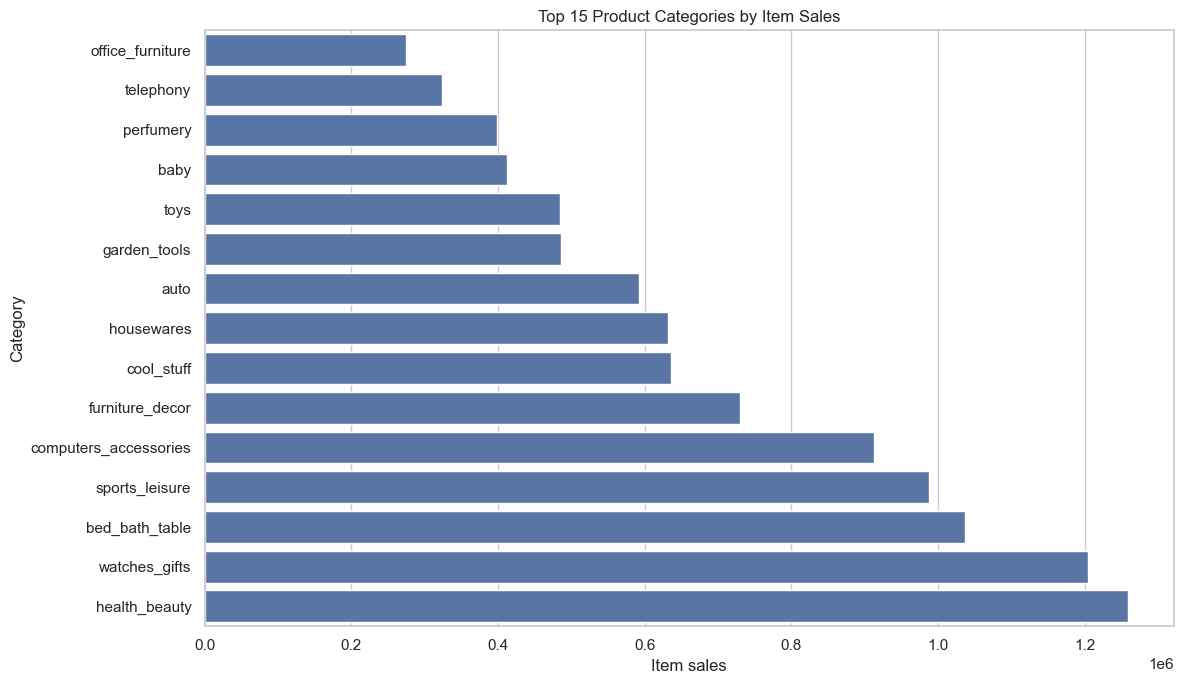

In [15]:
top_categories = (
    category_summary.head(15)
    .sort_values("item_sales")
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=top_categories,
    x="item_sales",
    y="category"
)
plt.title("Top 15 Product Categories by Item Sales")
plt.xlabel("Item sales")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

In [16]:
category_summary["sales_per_order"] = (
    category_summary["item_sales"] /
    category_summary["order_count"]
)

display(
    category_summary.sort_values(
        "order_count", ascending=False
    ).head(20)
)

,category,item_sales,order_count,item_lines,unique_products,sales_share_pct,sales_per_order
8,bed_bath_table,1036988.68,9417,11115,3029,7.629605,110.118794
44,health_beauty,1258681.34,8836,9670,2444,9.260700,142.449224
68,sports_leisure,988048.97,7720,8641,2867,7.269533,127.985618
16,computers_accessories,911954.32,6689,7827,1639,6.709669,136.336421
40,furniture_decor,729762.49,6449,8334,2657,5.369200,113.159015
50,housewares,632248.66,5884,6964,2335,4.651745,107.452186
73,watches_gifts,1205005.68,5624,5991,1329,8.865783,214.261323
71,telephony,323667.53,4199,4545,1134,2.381372,77.082050
6,auto,592720.11,3897,4235,1900,4.360916,152.096513
72,toys,483946.60,3886,4117,1411,3.560619,124.535924


In [17]:
print("Customer records:", len(customers))
print("Unique customer IDs:", customers["customer_id"].nunique())
print(
    "Unique customer identities:",
    customers["customer_unique_id"].nunique()
)

customer_orders = orders.merge(
    customers[
        ["customer_id", "customer_unique_id",
         "customer_city", "customer_state"]
    ],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

customer_frequency = (
    customer_orders.groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        first_order=("order_purchase_timestamp", "min"),
        last_order=("order_purchase_timestamp", "max")
    )
    .reset_index()
)

display(customer_frequency["total_orders"].describe())

Customer records: 99441
Unique customer IDs: 99441
Unique customer identities: 96096


count    96096.000000
mean         1.034809
std          0.214384
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         17.000000
Name: total_orders, dtype: float64

In [18]:
repeat_summary = (
    customer_frequency["total_orders"]
    .value_counts()
    .sort_index()
    .rename_axis("orders_per_customer")
    .reset_index(name="customer_count")
)

repeat_summary["customer_share_pct"] = (
    repeat_summary["customer_count"] /
    repeat_summary["customer_count"].sum() * 100
)

display(repeat_summary.head(15))

repeat_customer_pct = (
    customer_frequency["total_orders"].gt(1).mean() * 100
)

print(
    f"Customers with multiple orders in the observed dataset: "
    f"{repeat_customer_pct:.2f}%"
)

,orders_per_customer,customer_count,customer_share_pct
0,1,93099,96.881244
1,2,2745,2.856518
2,3,203,0.211247
3,4,30,0.031219
4,5,8,0.008325
5,6,6,0.006244
6,7,3,0.003122
7,9,1,0.001041
8,17,1,0.001041


Customers with multiple orders in the observed dataset: 3.12%


In [19]:
state_customers = (
    customer_orders.groupby("customer_state")
    .agg(
        orders=("order_id", "nunique"),
        customer_records=("customer_id", "nunique"),
        unique_customers=("customer_unique_id", "nunique")
    )
    .sort_values("orders", ascending=False)
    .reset_index()
)

display(state_customers.head(15))

,customer_state,orders,customer_records,unique_customers
0,SP,41746,41746,40302
1,RJ,12852,12852,12384
2,MG,11635,11635,11259
3,RS,5466,5466,5277
4,PR,5045,5045,4882
5,SC,3637,3637,3534
6,BA,3380,3380,3277
7,DF,2140,2140,2075
8,ES,2033,2033,1964
9,GO,2020,2020,1952


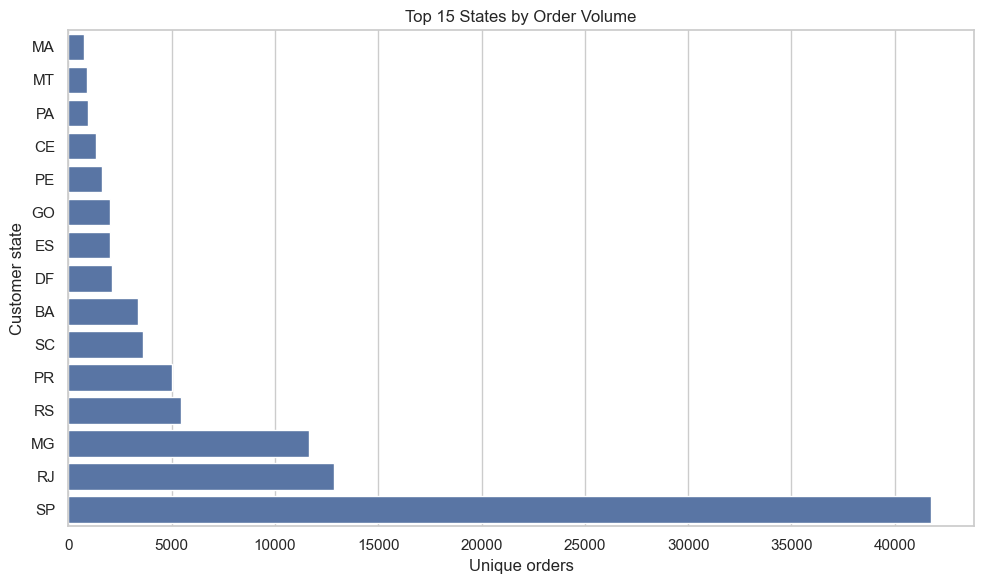

In [20]:
top_states = (
    state_customers.head(15)
    .sort_values("orders")
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=top_states,
    x="orders",
    y="customer_state"
)
plt.title("Top 15 States by Order Volume")
plt.xlabel("Unique orders")
plt.ylabel("Customer state")
plt.tight_layout()
plt.show()

In [21]:
delivery = orders.copy()

delivery["purchase_to_delivery_days"] = (
    delivery["order_delivered_customer_date"] -
    delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

delivery["delivery_delay_days"] = (
    delivery["order_delivered_customer_date"] -
    delivery["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

delivery["is_late"] = (
    delivery["delivery_delay_days"] > 0
)

delivered = delivery[
    delivery["order_delivered_customer_date"].notna()
].copy()

print("Orders with delivery timestamps:", len(delivered))

display(
    delivered[
        ["purchase_to_delivery_days", "delivery_delay_days"]
    ].describe(
        percentiles=[.5, .75, .90, .95, .99]
    )
)

print(
    "Late delivery rate:",
    round(delivered["is_late"].mean() * 100, 2),
    "%"
)

Orders with delivery timestamps: 96476


,purchase_to_delivery_days,delivery_delay_days
count,96476.000000,96476.000000
mean,12.558659,-11.179505
std,9.546533,10.186111
min,0.533333,-146.016667
50%,10.218056,-11.949306
75%,15.720139,-6.390278
90%,23.097569,-1.137847
95%,29.275694,3.818056
99%,46.050000,18.939236
max,209.628472,188.975000


Late delivery rate: 8.11 %


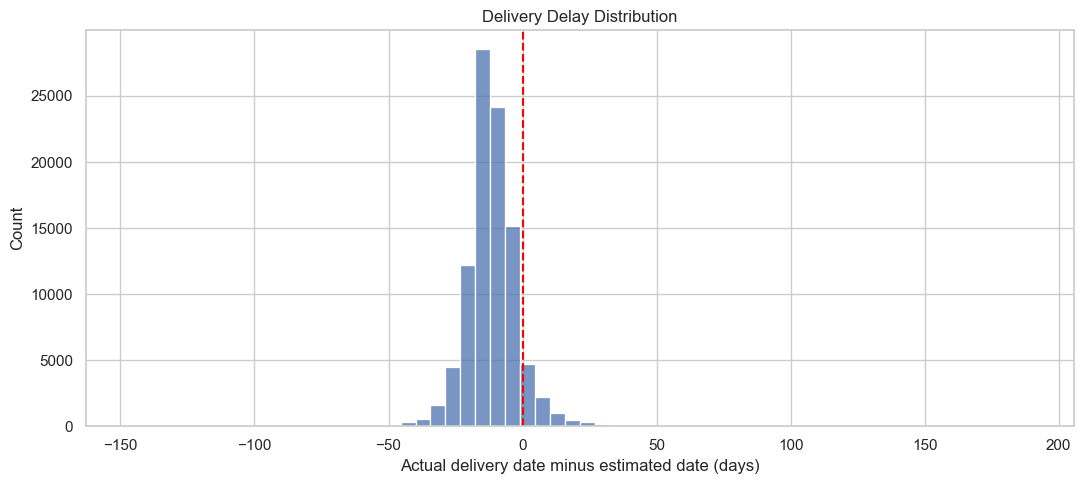

In [22]:
plt.figure(figsize=(11, 5))

sns.histplot(
    delivered["delivery_delay_days"].dropna(),
    bins=60
)

plt.axvline(0, color="red", linestyle="--")
plt.title("Delivery Delay Distribution")
plt.xlabel("Actual delivery date minus estimated date (days)")
plt.tight_layout()
plt.show()

In [23]:
stage_pairs = [
    (
        "order_purchase_timestamp",
        "order_approved_at",
        "purchase_to_approval_hours"
    ),
    (
        "order_approved_at",
        "order_delivered_carrier_date",
        "approval_to_carrier_days"
    ),
    (
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "carrier_to_customer_days"
    )
]

stage_results = []

for start, end, label in stage_pairs:
    duration = (
        orders[end] - orders[start]
    ).dt.total_seconds()

    if label.endswith("hours"):
        duration = duration / 3600
    else:
        duration = duration / 86400

    stage_results.append({
        "stage": label,
        "valid_records": duration.notna().sum(),
        "median_duration": duration.median(),
        "90th_percentile": duration.quantile(0.90),
        "negative_durations": (duration < 0).sum()
    })

display(pd.DataFrame(stage_results))

,stage,valid_records,median_duration,90th_percentile,negative_durations
0,purchase_to_approval_hours,99281,0.350000,34.666667,0
1,approval_to_carrier_days,97644,1.818750,5.997917,1358
2,carrier_to_customer_days,96475,7.099306,18.900139,23


In [24]:
delivery_geo = delivered.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

state_delivery = (
    delivery_geo.groupby("customer_state")
    .agg(
        delivered_orders=("order_id", "nunique"),
        median_delivery_days=("purchase_to_delivery_days", "median"),
        median_delay_days=("delivery_delay_days", "median"),
        late_rate=("is_late", "mean")
    )
    .reset_index()
)

state_delivery["late_rate_pct"] = (
    state_delivery["late_rate"] * 100
)

display(
    state_delivery.sort_values(
        "delivered_orders", ascending=False
    ).head(20)
)

,customer_state,delivered_orders,median_delivery_days,median_delay_days,late_rate,late_rate_pct
25,SP,40495,7.210417,-10.283333,0.058946,5.894555
18,RJ,12353,12.041667,-12.255556,0.134704,13.470412
10,MG,11355,10.313889,-13.118750,0.056187,5.618670
22,RS,5344,13.177431,-14.028472,0.071482,7.148204
17,PR,4923,10.425694,-13.094444,0.049970,4.996953
23,SC,3547,13.016667,-12.085417,0.097547,9.754722
4,BA,3256,16.913889,-11.563889,0.140356,14.035627
6,DF,2080,11.365278,-12.064583,0.070673,7.067308
7,ES,1995,13.636806,-11.153472,0.122306,12.230576
8,GO,1957,13.949306,-12.305556,0.081758,8.175779


In [25]:
review_summary = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .rename_axis("review_score")
    .reset_index(name="review_count")
)

review_summary["share_pct"] = (
    review_summary["review_count"] /
    review_summary["review_count"].sum() * 100
)

display(review_summary)

print("Mean review score:", reviews["review_score"].mean())
print("Median review score:", reviews["review_score"].median())

low_score_pct = (
    reviews["review_score"].isin([1, 2]).mean() * 100
)

print(f"1–2 star review share: {low_score_pct:.2f}%")

,review_score,review_count,share_pct
0,1,11424,11.513344
1,2,3151,3.175643
2,3,8179,8.242965
3,4,19142,19.291704
4,5,57328,57.776344


Mean review score: 4.08642062404257
Median review score: 5.0
1–2 star review share: 14.69%


In [27]:
order_reviews = (
    reviews.groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        review_count=("review_score", "size")
    )
    .reset_index()
)

delivery_reviews = delivery.merge(
    order_reviews,
    on="order_id",
    how="left",
    validate="one_to_one"
)

valid_reviews = delivery_reviews.dropna(
    subset=["delivery_delay_days", "average_review_score"]
)

display(
    valid_reviews.groupby("is_late")
    .agg(
        orders=("order_id", "nunique"),
        mean_review=("average_review_score", "mean"),
        median_review=("average_review_score", "median")
    )
)

,orders,mean_review,median_review
is_late,,,
False,88168,4.294151,5.0
True,7662,2.566562,2.0


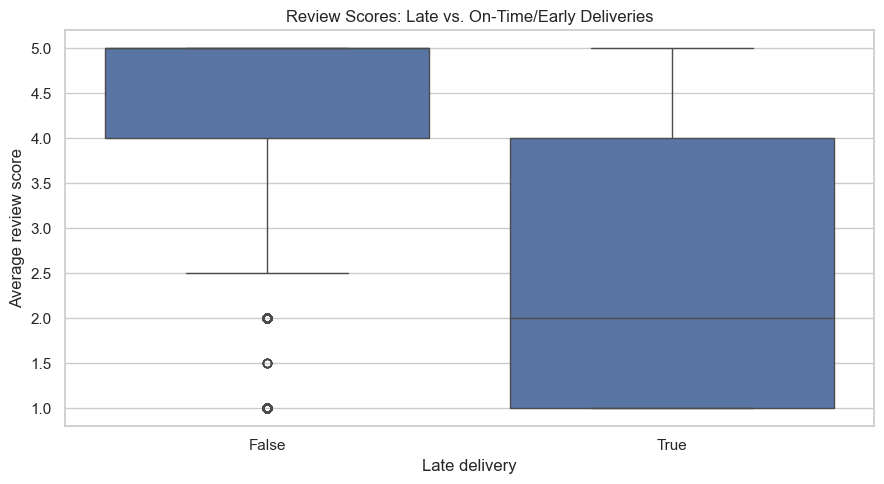

In [28]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=valid_reviews,
    x="is_late",
    y="average_review_score"
)

plt.title("Review Scores: Late vs. On-Time/Early Deliveries")
plt.xlabel("Late delivery")
plt.ylabel("Average review score")
plt.tight_layout()
plt.show()

In [29]:
print(
    "Correlation between delivery delay and review score:",
    valid_reviews["delivery_delay_days"].corr(
        valid_reviews["average_review_score"]
    )
)

Correlation between delivery delay and review score: -0.26664259400660845


In [30]:
status_reviews = (
    delivery_reviews.groupby("order_status")
    .agg(
        orders=("order_id", "nunique"),
        reviewed_orders=("average_review_score", "count"),
        average_score=("average_review_score", "mean"),
        median_score=("average_review_score", "median")
    )
    .reset_index()
)

display(status_reviews)

,order_status,orders,reviewed_orders,average_score,median_score
0,approved,2,2,2.500000,2.5
1,canceled,625,605,1.800000,1.0
2,created,5,3,2.333333,1.0
3,delivered,96478,95832,4.156187,5.0
4,invoiced,314,309,1.642395,1.0
5,processing,301,295,1.271186,1.0
6,shipped,1107,1032,2.002422,1.0
7,unavailable,609,595,1.530252,1.0


In [31]:
seller_sales = (
    order_items.groupby("seller_id")
    .agg(
        item_sales=("price", "sum"),
        freight=("freight_value", "sum"),
        order_count=("order_id", "nunique"),
        item_lines=("order_id", "size"),
        products_sold=("product_id", "nunique")
    )
    .reset_index()
)

seller_sales = seller_sales.merge(
    sellers[["seller_id", "seller_city", "seller_state"]],
    on="seller_id",
    how="left",
    validate="one_to_one"
)

seller_sales["sales_per_order"] = (
    seller_sales["item_sales"] /
    seller_sales["order_count"]
)

seller_sales = seller_sales.sort_values(
    "item_sales", ascending=False
)

display(seller_sales.head(20))

,seller_id,item_sales,freight,order_count,item_lines,products_sold,seller_city,seller_state,sales_per_order
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,20168.07,1132,1156,95,guariba,SP,202.714337
1013,53243585a1d6dc2643021fd1853d8905,222776.05,13080.63,358,410,23,lauro de freitas,BA,622.279469
881,4a3ca9315b744ce9f8e9374361493884,200472.92,35067.04,1806,1987,399,ibitinga,SP,111.003832
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,10042.70,585,586,289,sumare,SP,331.695778
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89,51612.55,982,1364,198,itaquaquecetuba,SP,191.368523
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87,6322.18,336,340,186,barueri,SP,525.094851
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,24955.75,1314,1551,222,piracicaba,SP,121.945639
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53,20902.85,1160,1171,149,sao paulo,SP,122.194422
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,33892.14,915,1428,154,sao paulo,SP,151.878197
1824,955fee9216a65b617aa5c0531780ce60,135171.70,25430.98,1287,1499,104,sao paulo,SP,105.028516


In [32]:
seller_sales["sales_share_pct"] = (
    seller_sales["item_sales"] /
    seller_sales["item_sales"].sum() * 100
)

seller_sales["cumulative_sales_share_pct"] = (
    seller_sales["sales_share_pct"].cumsum()
)

top_10_share = seller_sales.head(10)["sales_share_pct"].sum()

top_1_pct_count = max(
    1, int(np.ceil(len(seller_sales) * 0.01))
)

top_1_pct_share = (
    seller_sales.head(top_1_pct_count)["sales_share_pct"].sum()
)

print(f"Top 10 sellers' share of item sales: {top_10_share:.2f}%")
print(f"Top 1% sellers' share of item sales: {top_1_pct_share:.2f}%")

display(
    seller_sales[
        [
            "seller_id",
            "item_sales",
            "sales_share_pct",
            "cumulative_sales_share_pct"
        ]
    ].head(20)
)

Top 10 sellers' share of item sales: 13.15%
Top 1% sellers' share of item sales: 26.07%


,seller_id,item_sales,sales_share_pct,cumulative_sales_share_pct
857,4869f7a5dfa277a7dca6462dcf3b52b2,229472.63,1.688336,1.688336
1013,53243585a1d6dc2643021fd1853d8905,222776.05,1.639066,3.327402
881,4a3ca9315b744ce9f8e9374361493884,200472.92,1.474972,4.802374
3024,fa1c13f2614d7b5c4749cbc52fecda94,194042.03,1.427657,6.230031
1535,7c67e1448b00f6e969d365cea6b010ab,187923.89,1.382643,7.612674
1560,7e93a43ef30c4f03f38b393420bc753a,176431.87,1.298091,8.910765
2643,da8622b14eb17ae2831f4ac5b9dab84a,160236.57,1.178934,10.089699
1505,7a67c85e85bb2ce8582c35f2203ad736,141745.53,1.042887,11.132586
192,1025f0e2d44d7041d6cf58b6550e0bfa,138968.55,1.022456,12.155042
1824,955fee9216a65b617aa5c0531780ce60,135171.70,0.994521,13.149563


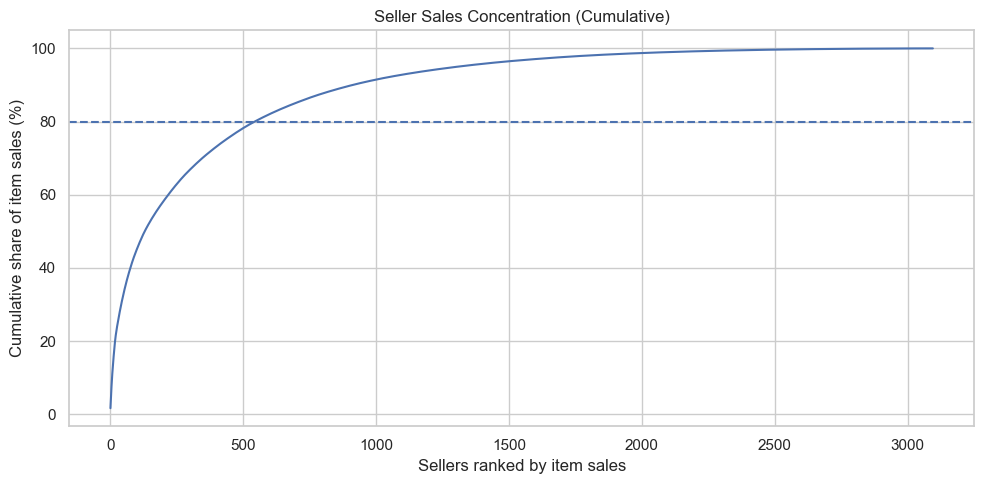

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    np.arange(1, len(seller_sales) + 1),
    seller_sales["cumulative_sales_share_pct"]
)

plt.axhline(80, linestyle="--")
plt.title("Seller Sales Concentration (Cumulative)")
plt.xlabel("Sellers ranked by item sales")
plt.ylabel("Cumulative share of item sales (%)")
plt.tight_layout()
plt.show()

In [34]:
seller_state_summary = (
    seller_sales.groupby("seller_state")
    .agg(
        sellers=("seller_id", "nunique"),
        item_sales=("item_sales", "sum"),
        orders=("order_count", "sum")
    )
    .sort_values("item_sales", ascending=False)
    .reset_index()
)

display(seller_state_summary.head(20))

,seller_state,sellers,item_sales,orders
0,SP,1849,8753396.21,70950
1,PR,349,1261887.21,7717
2,MG,244,1011564.74,7942
3,RJ,171,843984.22,4355
4,SC,190,632426.07,3672
5,RS,129,378559.54,1991
6,BA,19,285561.56,569
7,DF,30,97749.48,824
8,PE,9,91493.85,406
9,GO,40,66399.21,463


In [35]:
payment_summary = (
    payments.groupby("payment_type")
    .agg(
        payment_records=("payment_type", "size"),
        orders=("order_id", "nunique"),
        payment_value=("payment_value", "sum")
    )
    .reset_index()
    .sort_values("payment_value", ascending=False)
)

payment_summary["value_share_pct"] = (
    payment_summary["payment_value"] /
    payment_summary["payment_value"].sum() * 100
)

display(payment_summary)

,payment_type,payment_records,orders,payment_value,value_share_pct
1,credit_card,76795,76505,12542084.19,78.344584
0,boleto,19784,19784,2869361.27,17.923569
4,voucher,5775,3866,379436.87,2.370166
2,debit_card,1529,1528,217989.79,1.361681
3,not_defined,3,3,0.00,0.000000


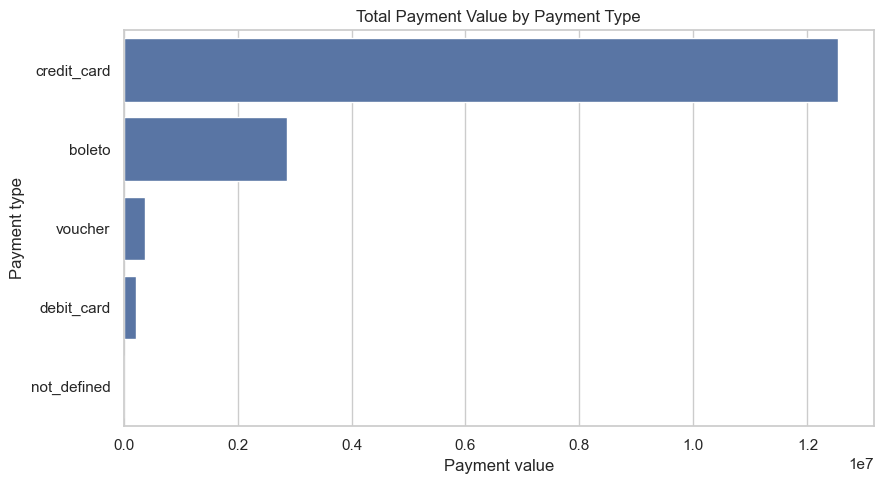

In [36]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=payment_summary,
    x="payment_value",
    y="payment_type"
)

plt.title("Total Payment Value by Payment Type")
plt.xlabel("Payment value")
plt.ylabel("Payment type")
plt.tight_layout()
plt.show()

,payment_records,median_installments,mean_installments
payment_type,,,
credit_card,76795,3.0,3.507155
boleto,19784,1.0,1.000000
voucher,5775,1.0,1.000000
debit_card,1529,1.0,1.000000
not_defined,3,1.0,1.000000


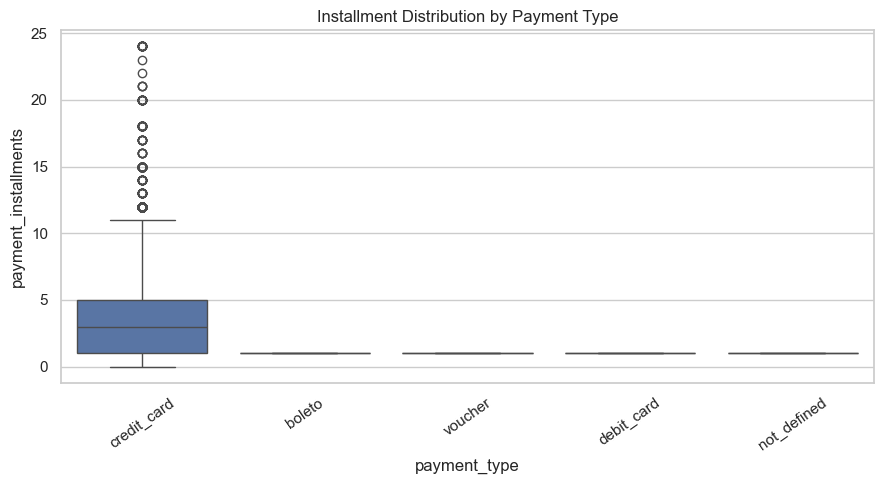

In [37]:
if "payment_installments" in payments.columns:
    display(
        payments.groupby("payment_type")
        .agg(
            payment_records=("payment_type", "size"),
            median_installments=("payment_installments", "median"),
            mean_installments=("payment_installments", "mean")
        )
        .sort_values("payment_records", ascending=False)
    )

    plt.figure(figsize=(9, 5))
    sns.boxplot(
        data=payments,
        x="payment_type",
        y="payment_installments"
    )
    plt.title("Installment Distribution by Payment Type")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

In [38]:
payment_order = (
    payments.groupby("order_id")
    .agg(payment_total=("payment_value", "sum"))
    .reset_index()
)

reconciliation = order_sales.merge(
    payment_order,
    on="order_id",
    how="outer",
    indicator=True,
    validate="one_to_one"
)

reconciliation["items_plus_freight"] = (
    reconciliation["item_revenue"].fillna(0) +
    reconciliation["freight_revenue"].fillna(0)
)

reconciliation["payment_difference"] = (
    reconciliation["payment_total"] -
    reconciliation["items_plus_freight"]
)

display(reconciliation["_merge"].value_counts())

display(
    reconciliation["payment_difference"]
    .describe(percentiles=[.01, .05, .5, .95, .99])
)

_merge
both          98665
right_only      775
left_only         1
Name: count, dtype: int64

count    9.944000e+04
mean     1.663941e+00
std      3.675264e+01
min     -5.162000e+01
1%      -5.684342e-14
5%      -1.421085e-14
50%      0.000000e+00
95%      1.421085e-14
99%      1.632700e+00
max      3.782190e+03
Name: payment_difference, dtype: float64

In [39]:
largest_differences = (
    reconciliation.assign(
        abs_difference=reconciliation["payment_difference"].abs()
    )
    .sort_values("abs_difference", ascending=False)
    .head(20)
)

display(
    largest_differences[
        [
            "order_id",
            "item_revenue",
            "freight_revenue",
            "payment_total",
            "payment_difference",
            "_merge"
        ]
    ]
)

,order_id,item_revenue,freight_revenue,payment_total,payment_difference,_merge
97935,fc20b8e282da6f3fbcdd3a3cedecb723,NaN,NaN,3782.19,3782.19,right_only
1224,03310aa823a66056268a3bab36e827fb,NaN,NaN,3184.34,3184.34,right_only
46576,7813842ae95e8c497fc0233232ae815a,NaN,NaN,3184.34,3184.34,right_only
2280,05c852fbe20c108caf9f479633cbe088,NaN,NaN,2345.03,2345.03,right_only
68048,afb61112fb99b07fe17e591c68c0c84c,NaN,NaN,2266.61,2266.61,right_only
17172,2c990009034e1fc83904584b26b5fd25,NaN,NaN,2234.70,2234.70,right_only
69962,b465e6231fb8411e534acc602cff4adb,NaN,NaN,2125.19,2125.19,right_only
21232,36cde427894b4797db8316e92b8e58f2,NaN,NaN,2116.01,2116.01,right_only
17146,2c885b285dce307562d7f4caae89c6dc,NaN,NaN,2039.44,2039.44,right_only
31622,51375acfdef4d742df94640aa60d385b,NaN,NaN,1643.64,1643.64,right_only


In [40]:
seller_delivery_data = order_items[
    ["order_id", "seller_id"]
].drop_duplicates().merge(
    delivered[
        [
            "order_id",
            "delivery_delay_days",
            "is_late",
            "purchase_to_delivery_days"
        ]
    ],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

seller_delivery_summary = (
    seller_delivery_data.groupby("seller_id")
    .agg(
        delivered_orders=("order_id", "nunique"),
        median_delay_days=("delivery_delay_days", "median"),
        late_rate=("is_late", "mean"),
        median_transit_days=("purchase_to_delivery_days", "median")
    )
    .reset_index()
)

seller_delivery_summary["late_rate_pct"] = (
    seller_delivery_summary["late_rate"] * 100
)

# Exclude very small samples for more stable comparisons.
reliable_sellers = seller_delivery_summary[
    seller_delivery_summary["delivered_orders"] >= 30
].sort_values("late_rate_pct", ascending=False)

display(reliable_sellers.head(20))

,seller_id,delivered_orders,median_delay_days,late_rate,median_transit_days,late_rate_pct
2766,ede0c03645598cdfc63ca8237acbe73d,43,-6.265278,0.348837,15.284722,34.883721
2011,ad781527c93d00d89a11eecd9dcad7c1,38,-8.657986,0.315789,21.278472,31.578947
1556,835f0f7810c76831d6c7d24c7a646d4d,42,-4.170139,0.309524,18.277778,30.952381
1000,54965bbe3e4f07ae045b90b0b8541f52,73,-8.185417,0.301370,16.542361,30.136986
478,2a1348e9addc1af5aaa619b1a3679d6b,48,-9.267708,0.270833,13.160417,27.083333
1209,66e0557ecc2b4dbea057e93f215f68d8,30,-9.620139,0.266667,29.353819,26.666667
1928,a49928bcdf77c55c6d6e05e09a9b4ca5,96,-6.128472,0.260417,13.847222,26.041667
2781,ef990a83bbea832f36ebe81376335aa8,43,-11.163194,0.255814,13.806250,25.581395
2211,beadbee30901a7f61d031b6b686095ad,64,-8.071528,0.250000,9.813194,25.000000
79,06a2c3af7b3aee5d69171b0e14f0ee87,389,-11.331944,0.231362,15.718056,23.136247


In [41]:
item_review_data = (
    order_items.groupby("order_id")
    .agg(
        order_item_sales=("price", "sum"),
        item_count=("order_item_id", "count")
    )
    .reset_index()
    .merge(
        order_reviews,
        on="order_id",
        how="inner",
        validate="one_to_one"
    )
)

item_review_data["sales_quartile"] = pd.qcut(
    item_review_data["order_item_sales"],
    q=4,
    labels=["Q1 - Low", "Q2", "Q3", "Q4 - High"],
    duplicates="drop"
)

display(
    item_review_data.groupby("sales_quartile", observed=True)
    .agg(
        orders=("order_id", "nunique"),
        average_sales=("order_item_sales", "mean"),
        average_review=("average_review_score", "mean"),
        low_review_share=(
            "average_review_score",
            lambda x: x.isin([1, 2]).mean() * 100
        )
    )
)

,orders,average_sales,average_review,low_review_share
sales_quartile,,,,
Q1 - Low,24593,28.588496,4.171316,12.096938
Q2,24467,63.948496,4.130625,13.373115
Q3,24516,115.101678,4.112416,13.937837
Q4 - High,24341,344.168585,4.004992,17.160347


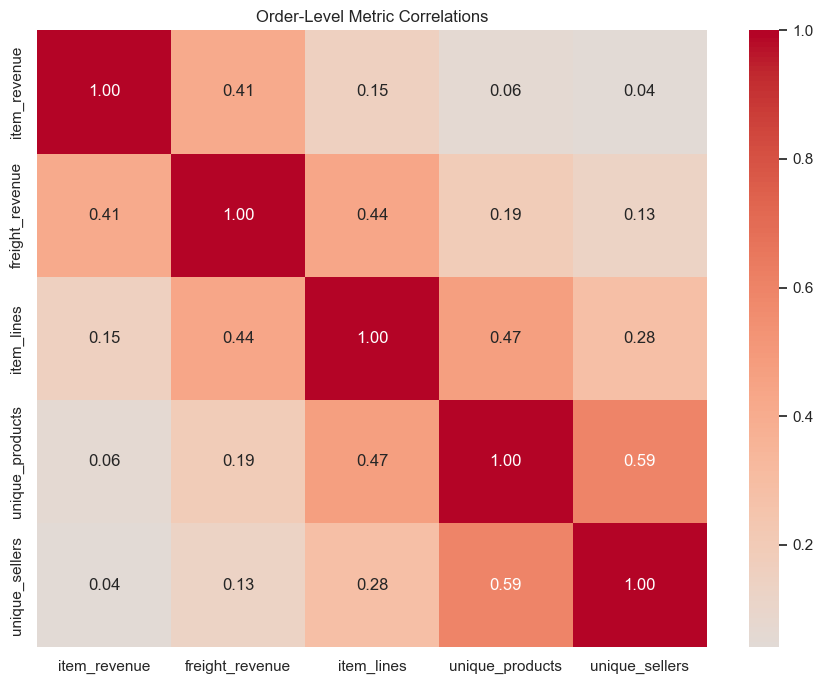

In [42]:
numeric_metrics = [
    "item_revenue",
    "freight_revenue",
    "item_lines",
    "unique_products",
    "unique_sellers"
]

correlation_matrix = order_sales[numeric_metrics].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Order-Level Metric Correlations")
plt.tight_layout()
plt.show()

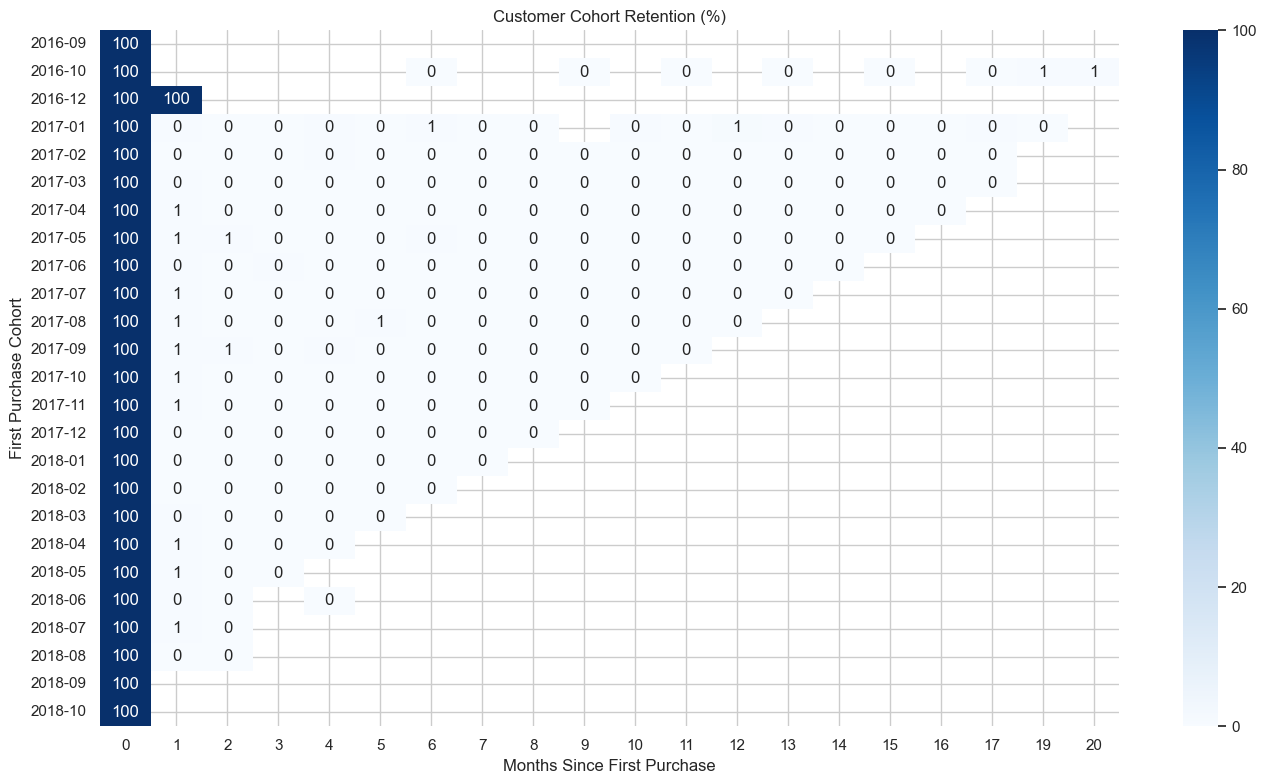

In [43]:
cohort_data = customer_orders[
    ["customer_unique_id", "order_id", "order_purchase_timestamp"]
].dropna().copy()

cohort_data["order_month"] = (
    cohort_data["order_purchase_timestamp"].dt.to_period("M")
)

cohort_data["cohort_month"] = (
    cohort_data.groupby("customer_unique_id")["order_month"]
    .transform("min")
)

cohort_data["cohort_index"] = (
    (cohort_data["order_month"].dt.year -
     cohort_data["cohort_month"].dt.year) * 12
    + cohort_data["order_month"].dt.month
    - cohort_data["cohort_month"].dt.month
)

cohort_counts = (
    cohort_data.groupby(["cohort_month", "cohort_index"])
    ["customer_unique_id"]
    .nunique()
    .unstack()
)

cohort_retention = cohort_counts.div(
    cohort_counts[0],
    axis=0
) * 100

plt.figure(figsize=(14, 8))
sns.heatmap(
    cohort_retention,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    vmin=0,
    vmax=100
)

plt.title("Customer Cohort Retention (%)")
plt.xlabel("Months Since First Purchase")
plt.ylabel("First Purchase Cohort")
plt.tight_layout()
plt.show()

In [44]:
kpis = {
    "Total order records": len(orders),
    "Unique orders": orders["order_id"].nunique(),
    "Unique customer identities": customers["customer_unique_id"].nunique(),
    "Active sellers in item data": order_items["seller_id"].nunique(),
    "Distinct products sold": order_items["product_id"].nunique(),
    "Total item sales": order_items["price"].sum(),
    "Total freight": order_items["freight_value"].sum(),
    "Total payment value": payments["payment_value"].sum(),
    "Average review score": reviews["review_score"].mean(),
    "Late delivery rate (%)": delivered["is_late"].mean() * 100,
    "Median delivery duration (days)": delivered["purchase_to_delivery_days"].median()
}

kpi_summary = pd.DataFrame(
    kpis.items(),
    columns=["KPI", "Value"]
)

display(kpi_summary)

,KPI,Value
0,Total order records,9.944100e+04
1,Unique orders,9.944100e+04
2,Unique customer identities,9.609600e+04
3,Active sellers in item data,3.095000e+03
4,Distinct products sold,3.295100e+04
5,Total item sales,1.359164e+07
6,Total freight,2.251910e+06
7,Total payment value,1.600887e+07
8,Average review score,4.086421e+00
9,Late delivery rate (%),8.112899e+00


In [47]:
from pathlib import Path

output_dir = Path("olist_eda_outputs")
output_dir.mkdir(exist_ok=True)

for name, df in dfs.items():
    df.to_csv(
        output_dir / f"{name}_cleaned.csv",
        index=False
    )

profile_df.to_csv(
    output_dir / "data_profile.csv",
    index=False
)

missing_df.to_csv(
    output_dir / "missing_values_report.csv",
    index=False
)

reconciliation.to_csv(
    output_dir / "payment_reconciliation.csv",
    index=False
)

master.to_csv(
    output_dir / "master_analytical_dataset.csv",
    index=False
)

print("Exports saved to:", output_dir.resolve())

NameError: name 'profile_df' is not defined

# Predictive Model using your 9 Olist data files

In [34]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib streamlit

  Attempting uninstall: protobuf
    Found existing installation: protobuf 7.35.0
    Uninstalling protobuf-7.35.0:
      Successfully uninstalled protobuf-7.35.0
Note: you may need to restart the kernel to use updated packages.


In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from pathlib import Path

In [36]:
orders_ml = orders.copy()
items_ml = order_items.copy()
customers_ml = customers.copy()
products_ml = products.copy()
sellers_ml = sellers.copy()

date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    orders_ml[col] = pd.to_datetime(
        orders_ml[col], errors="coerce"
    )

print("Orders:", orders_ml.shape)
print("Items:", items_ml.shape)

Orders: (99441, 8)
Items: (112650, 7)


In [37]:
item_summary = (
    items_ml.groupby("order_id")
    .agg(
        item_count=("order_item_id", "count"),
        item_value=("price", "sum"),
        freight_value=("freight_value", "sum"),
        seller_count=("seller_id", "nunique"),
        product_count=("product_id", "nunique")
    )
    .reset_index()
)

In [38]:
customer_features = customers_ml[
    ["customer_id", "customer_state"]
].drop_duplicates("customer_id")

In [39]:
ml_data = orders_ml.merge(
    item_summary,
    on="order_id",
    how="left",
    validate="one_to_one"
)

ml_data = ml_data.merge(
    customer_features,
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Keep orders with observed delivery outcomes
ml_data = ml_data[
    ml_data["order_status"].eq("delivered")
    & ml_data["order_delivered_customer_date"].notna()
    & ml_data["order_estimated_delivery_date"].notna()
].copy()

ml_data["late_delivery"] = (
    ml_data["order_delivered_customer_date"]
    > ml_data["order_estimated_delivery_date"]
).astype(int)

print(ml_data["late_delivery"].value_counts())
print(ml_data["late_delivery"].value_counts(normalize=True).round(3))

late_delivery
0    88644
1     7826
Name: count, dtype: int64
late_delivery
0    0.919
1    0.081
Name: proportion, dtype: float64


In [40]:
ml_data["purchase_month"] = (
    ml_data["order_purchase_timestamp"].dt.month
)

ml_data["purchase_day_of_week"] = (
    ml_data["order_purchase_timestamp"].dt.dayofweek
)

ml_data["purchase_hour"] = (
    ml_data["order_purchase_timestamp"].dt.hour
)

ml_data["estimated_delivery_days"] = (
    ml_data["order_estimated_delivery_date"]
    - ml_data["order_purchase_timestamp"]
).dt.total_seconds() / 86400

ml_data["estimated_delivery_days"] = (
    ml_data["estimated_delivery_days"].clip(lower=0)
)

In [41]:
feature_cols = [
    "customer_state",
    "purchase_month",
    "purchase_day_of_week",
    "purchase_hour",
    "estimated_delivery_days",
    "item_count",
    "item_value",
    "freight_value",
    "seller_count",
    "product_count"
]

X = ml_data[feature_cols].copy()
y = ml_data["late_delivery"].copy()

print("Features:", X.shape)
print("Target:", y.shape)

Features: (96470, 10)
Target: (96470,)


In [42]:
ml_data = ml_data.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

X = ml_data[feature_cols]
y = ml_data["late_delivery"]

split_index = int(len(ml_data) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training late rate:", round(y_train.mean(), 3))
print("Testing late rate:", round(y_test.mean(), 3))

Training rows: 77176
Testing rows: 19294
Training late rate: 0.088
Testing late rate: 0.053


In [43]:
categorical_features = ["customer_state"]

numeric_features = [
    col for col in feature_cols
    if col not in categorical_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [44]:
logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


In [45]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

print("Random Forest training completed.")

Random Forest training completed.


In [46]:
models = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC AUC": (
            roc_auc_score(y_test, probabilities)
            if y_test.nunique() == 2 else np.nan
        )
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision,Recall,F1 Score,ROC AUC
Model,,,,,
Logistic Regression,0.5563,0.0929,0.8423,0.1673,0.7223
Random Forest,0.8968,0.0917,0.1068,0.0986,0.7337


Model selected by test F1-score: Logistic Regression


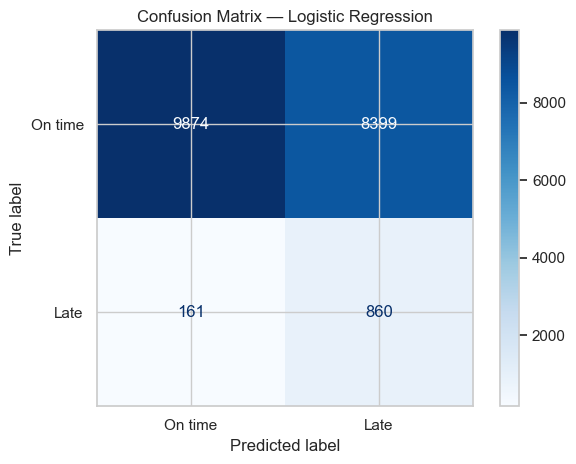

In [47]:
best_model_name = results_df["F1 Score"].idxmax()
best_model = models[best_model_name]

print("Model selected by test F1-score:", best_model_name)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_model.predict(X_test),
    display_labels=["On time", "Late"],
    cmap="Blues"
)

plt.title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

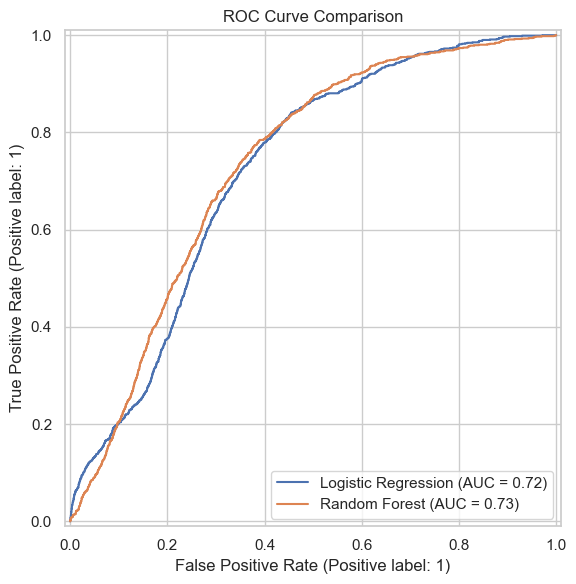

In [48]:
if y_test.nunique() == 2:
    fig, ax = plt.subplots(figsize=(7, 6))

    for name, model in models.items():
        RocCurveDisplay.from_estimator(
            model, X_test, y_test,
            name=name, ax=ax
        )

    plt.title("ROC Curve Comparison")
    plt.tight_layout()
    plt.show()

,Feature,Importance
3,numeric__estimated_delivery_days,0.215820
0,numeric__purchase_month,0.169423
6,numeric__freight_value,0.164967
5,numeric__item_value,0.134595
2,numeric__purchase_hour,0.088834
1,numeric__purchase_day_of_week,0.056209
34,categorical__customer_state_SP,0.044503
27,categorical__customer_state_RJ,0.024165
19,categorical__customer_state_MG,0.015960
4,numeric__item_count,0.010611


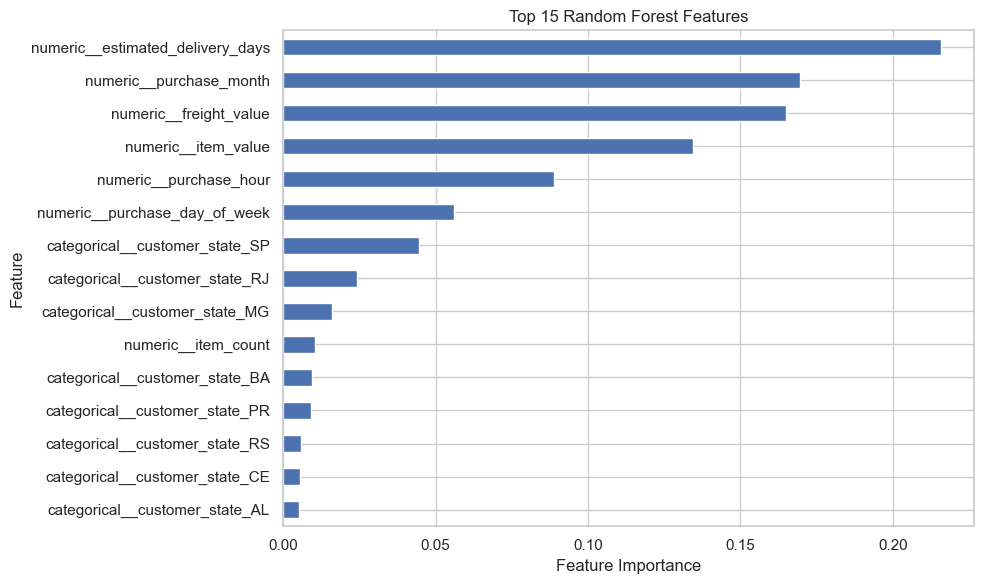

In [49]:
rf_preprocessor = rf_model.named_steps["preprocessor"]
rf_classifier = rf_model.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()
importances = rf_classifier.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(15))

importance_df.head(15).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    figsize=(10, 6),
    legend=False
)

plt.title("Top 15 Random Forest Features")
plt.xlabel("Feature Importance")
plt.tight_layout()
plt.show()

In [50]:
output_dir = Path("model_artifacts")
output_dir.mkdir(exist_ok=True)

joblib.dump(
    {
        "model": best_model,
        "features": feature_cols,
        "model_name": best_model_name,
        "target_definition": (
            "1 if actual delivery date is after estimated delivery date"
        )
    },
    output_dir / "late_delivery_model.joblib"
)

print("Model saved successfully.")

Model saved successfully.
